# Adjoint Kernel psi_hat: Numeric vs. Closed-Form Validation

Validates the numerically-computed adjoint kernel `psi_hat` — the same quantity computed by `calc_psi_hat()` in `common/adjoint_field_zernike.py` / `without_zernike/adjoint_field.py`, central to the adjoint-gradient derivation — against a closed-form analytic solution built from `scipy.special.expi`, for the simple case of a boxcar (top-hat) z-window `S`. Checks agreement both in k-space (`psi_hat` directly) and after inverse-Hankel-transforming back to r-space (`psi`), with difference plots between the numeric and analytic results.

This is a genuine independent check of the adjoint-gradient integral formula's correctness that was never ported into the current tested code — kept for that reason. (The cell below is the original notebook's project-level intro, kept as-is for context.)


# Adjoint Optimization of Mirror Shape for Flying Focus Acceleration

Goal is to set up an optimization algorithm to achieve a target pulse shape on axis from a radiation beam reflected from a mirror.

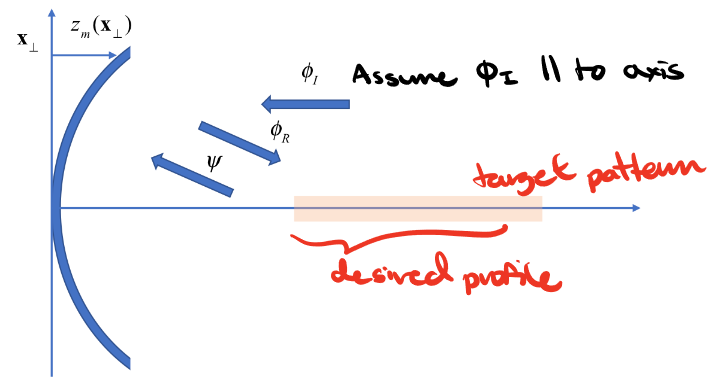

Surface of the mirror is defined by $z=z_m(x_{\perp})$. This is the function we want to optimize

Side note: Sagitta function of optic is defined as: $z(x_{\perp})=\frac{x_{\perp}^2}{R+\sqrt{R^2-(K+1)x_{\perp}^2}}$ where $R$ is the radius of curvature and $K$ is the conic constant

The incident wave $\phi_I$ (assume parallel to axis) comes from the right strikes the mirror and become a reflected wave, $\phi_R$. The reflected wave crosses the z-axis and creates a traveling pulse in the shaded region. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv,jn_zeros,expi
from scipy.optimize import curve_fit
from scipy.integrate import trapezoid,simpson,romb
from numpy.fft import *
import math
from gaussian_fn import *
font = {'size'   : 26}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (16,9)

In [2]:
def create_starting_optic(r,R,k=-1):
    z=r*r/(R+np.sqrt(R*R-(k+1)*r*r))
    return z

This function defines the r and k array for a Hankel Transform:

* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function


In [3]:
def DHTarrays(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

This function defines the Transform Matrix for the Hankel Transform
* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function
* `T_R2K` transforms from r space to k space
* `T_K2R` transforms from k space to r space


In [4]:
def DHTtransformMatrix(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    alpha=Zeroes[:N]
    kR = alpha[N-1]
    kmax = kR/R;
    T = jv(ell,np.outer(alpha,alpha)/kR) / np.outer( abs(jv(ell+1,alpha)),abs(jv(ell+1,alpha)) ) / kR;
    #print(T)
    A = abs(jv(ell+1,alpha));
    T_R2K = 4.0*np.pi*(R/kmax)*T * A[:, None] / A[None,:] 
    T_K2R = (1/np.pi)*(kmax/R)*T * A[:, None] / A[None,:] 

    return T_R2K,T_K2R

In [5]:
def propagate_1(fe,k,k0,z,T_R2K,T_K2R):
    # 1) fe is the initial electric field
    # 2) Hankel transform the field through multiplying by the appropriate transform matrix 
    FT = T_R2K@fe; # Hankel Transform
    # 3) Propagate 𝐸̃ from 𝑧 = 0 to 𝑧 = Δ𝑧 through multiplying 𝐸̃ by the diffractive phase:
    FT = FT * np.exp(-1j*k**2/(2*k0)*z[:,np.newaxis])
    # print(FT.shape)
    # print(T_K2R.shape)
    # 4) Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = (T_K2R@(FT.T)).T

    return fT

In [6]:
def propagate_2(fe,k,k0,zi,zf,nz,T_R2K,T_K2R):
    dz=(zf-zi)/nz
    
    FT=[]
#     prop=np.zeros((len(fe),nz))
    FT.append(T_R2K@fe); # Hankel Transform
    
    # 3) Propagate 𝐸̃ from 𝑧 = 0 to 𝑧 = zi through multiplying 𝐸̃ by the diffractive phase:
    for i in range(nz-1)+1:
        FT.append(FT[i-1]*np.exp(-1j*k**2/(2*k0)*dz))
    
    # print(FT.shape)
    # print(T_K2R.shape)
    # 4) Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = (T_K2R@FT)


In [7]:
def mirror(phiI,k0,zm):
    return phiI*np.exp(-2j*k0*zm)

In [8]:
def forward_propagation(w0,r,k,T_R2K,T_K2R,zI,zF,RoC,wavelength=1e-6,prop=propagate_1):
    k0= 2*np.pi/wavelength
    phi_I=np.exp(-(r/w0)**2)
    fT_i=prop(phi_I,k,k0,zI,T_R2K,T_K2R)
    zm=create_starting_optic(r,RoC) 
    phi_R0=mirror(fT_i[-1],k0,zm)
    
    fT_f=prop(phi_R0,k,k0,zF,T_R2K,T_K2R)
    
    return fT_i,fT_f

In [9]:
def difference(obs,exp):
    diff=np.abs(np.sum(np.abs(obs)**2)-np.sum(np.abs(exp)**2))/np.abs(np.sum(exp)**2)
    return diff

In [10]:
def retrieve_bounds(z,zi,zf):
    i=len(z[z-zi<0])
    f=len(z[z-zf<=0])
    return i,f

In [11]:
def w_xp(r,R):
    return np.exp(-r**2/R**2)

In [12]:
def w_z(z,zi,zf):
    i,f=retrieve_bounds(z,zi,zf)
    w=np.zeros(len(z))
    w[i:f]=1
    return w

In [13]:
def integrate(r,z,phi1,phi2,method=simpson):
    return np.abs(2*np.pi*method(method(phi1*np.conj(phi2)*r[:,np.newaxis],z),r))

In [14]:
def weighted_phi(r,R,z,zi,zf,phi_r,phi_t):
    pr=phi_r*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    pt=phi_t*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    return pr,pt

In [15]:
def int_pairs(r,z,pr,pt):
    phi_r_sq=integrate(r,z,pr,pr)
    phi_r_phi_t=integrate(r,z,pr,pt)
    phi_t_sq=integrate(r,z,pt,pt)
    return phi_r_sq,phi_r_phi_t,phi_t_sq

In [16]:
def FOM(prsq,prpt,ptsq):
    return 0.5*(prsq-prpt**2/ptsq)

In [17]:
def mu(prpt,ptsq):
    return prpt/ptsq

In [18]:
def S(pr,pt,prpt,ptsq):
    m=mu(prpt,ptsq)
    s=pr-m*pt
    return s

In [19]:
def calc_psi_hat(k,k0,z,s_hat,method=simpson):
    coeff=-1j/(2*k0)
    integrand=np.exp(-1j*np.outer(k**2,z)/(2*k0))*s_hat
    return coeff*method(integrand,z)

# Parameters:

All initial parameters are defined here. Default is in kms units

Lens Parameters
* `f` focal length of the lens
* `RoC` radius of curvature of the lens

Beam Parameters
* `wl` wavelength (m)
* `k0` wavenumber
* `w0` spot size (m) $\qquad f_\#=\frac{f}{w_0}$
* `rmax` maximum r value (m)
* `nr` number of points in radial direction
* `zR` rayleigh length

Distance Parameters
* `zi` starting distance away from the mirror
* `zf` final distance after encountering the mirror
* `nzi` number of points in z before the mirror
* `nzf` number of points in z after the mirror
* `zI` defining the z array before the mirror
* `zF` defining the z array after the mirror
* `wR` the diffraction limited spot size

Curve Fit Parameters to retrieve waist at different z locations
* `OoM` order of magnitude of the `w0`^2
* `w_guess` the initial spot size guess that is used to find the spot size 

In [20]:
# Lens parameters
f=0.05625
ell=0
# Beam Parameters
wl=1e-6
k0=2*np.pi/wl
fn=25
w0=f/(2*fn)
#w0=0.036
rmax=3*w0
nr=4000
zR=np.pi*w0**2/wl
wR=2/np.pi*fn*wl

# Distance parameters
# zi=0.1*zR
zi=0
zf=2*zM(f,w0**2,wavelength=wl) 
nzi=101
zI=np.linspace(0,zi,nzi)
zF=np.arange(0.03,0.07,2.5e-6)
nzf=len(zF)


# Guess parameters
OoM=math.floor(math.log(w0**2, 10))
w_guess=10**OoM
assert(w0>wR),"Spot size is smaller than diffraction limited spot size"

# Hankel Forward Propagation

In [21]:
[r,k] = DHTarrays(nr,rmax,ell)
[T_R2K,T_K2R] = DHTtransformMatrix(nr,rmax,ell)

In [ ]:
s_hat=np.ones((nr,nzf))*w_z(zF,0.04,0.06)

In [23]:
psi_hat= calc_psi_hat(k,k0,zF,s_hat)

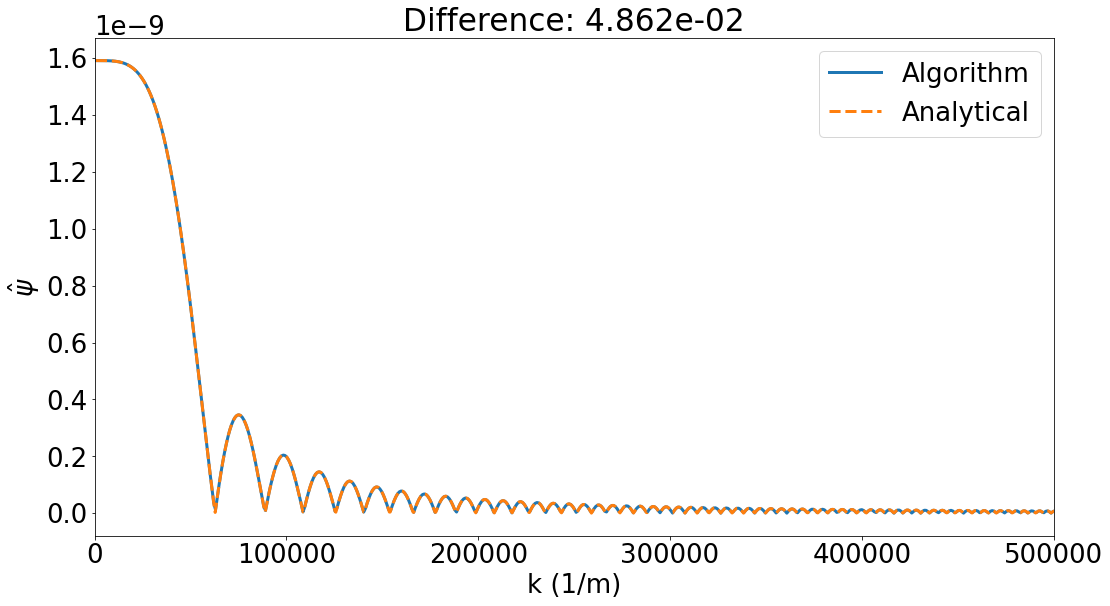

In [24]:
plt.plot(k,np.abs(psi_hat),linewidth=3,label='Algorithm')
kp=np.linspace(min(k),max(k),10000)
psi_hat=1/(kp**2)*(np.exp(-1j*kp**2*0.06/(2*k0))-np.exp(-1j*kp**2*0.04/(2*k0)))
plt.plot(kp,np.abs(psi_hat),linewidth=3,label='Analytical',linestyle='--')
plt.xlim((0,5e5))
plt.xlabel('k (1/m)')
plt.ylabel(r'$\hat{\psi}$')
plt.title('Difference: %.3e' %(difference(A_hat,psi_hat)))
plt.legend()
plt.tight_layout()
plt.savefig('psi_hat')

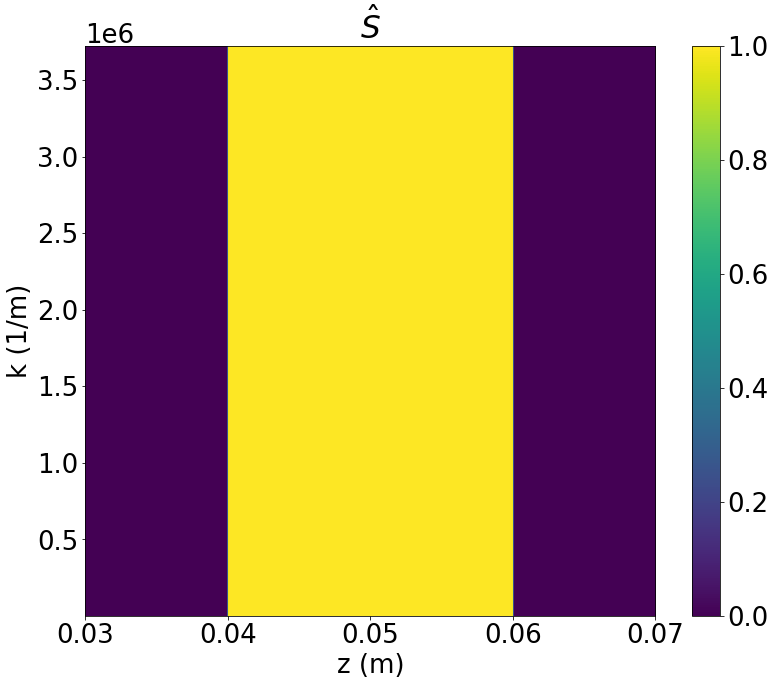

In [25]:
plt.figure(figsize=(12,10))
plt.imshow(s_hat,origin='lower',extent=[min(zF),max(zF),min(k),max(k)],aspect=(max(zF)-min(zF))/max(k))
plt.xlabel('z (m)')
plt.ylabel('k (1/m)')
plt.colorbar()
plt.title(r'$\hat{S}$')
plt.tight_layout()
plt.savefig("s_hat_c")

In [26]:
psi=1/(2*2*np.pi)*(expi(1j*k0*r**2/(2*0.06))-expi(1j*k0*r**2/(2*0.04)))

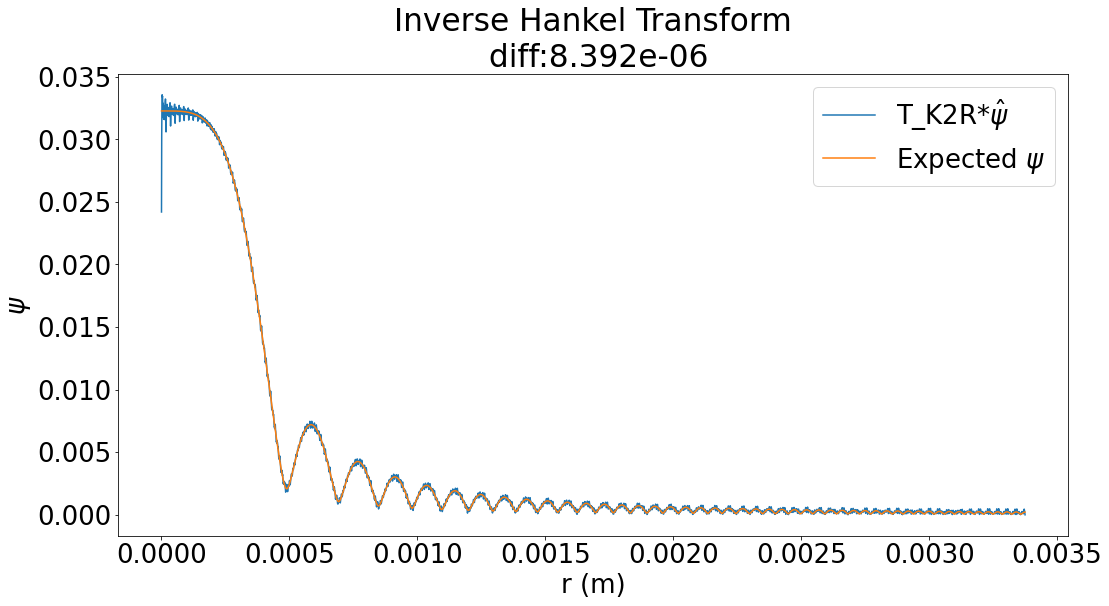

In [29]:
plt.plot(r,np.abs((T_K2R@psi_hat).T),label=r'T_K2R*$\hat{\psi}$')
plt.plot(r,np.abs(psi),label=r'Expected $\psi$')
#plt.xlim((0,1e-4))
plt.legend()
plt.xlabel('r (m)')
plt.ylabel(r'$\psi$')

plt.title('Inverse Hankel Transform\n diff:%.3e'%(difference((T_K2R@A_hat).T,psi)))
plt.tight_layout()
plt.savefig('IHT_A_hat')

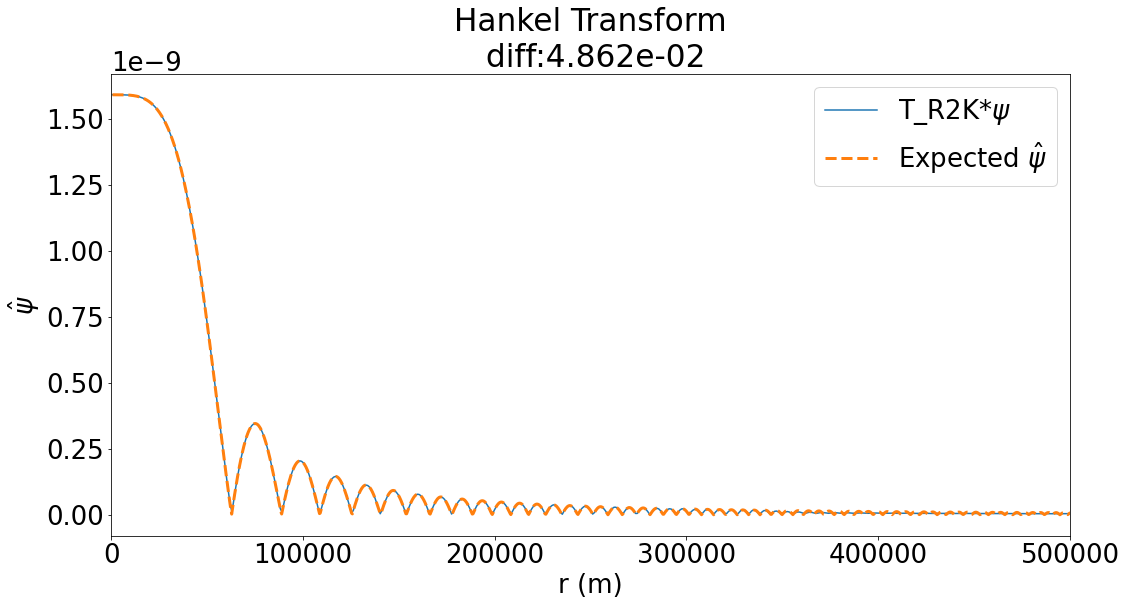

In [30]:
plt.plot(k,np.abs(T_R2K@psi),label=r'T_R2K*$\psi$')
plt.plot(kp,np.abs(psi_hat),linewidth=3,label=r'Expected $\hat{\psi}$',linestyle='--')
plt.xlim((0,5e5))
plt.legend()
plt.xlabel('r (m)')
plt.ylabel(r'$\hat{\psi}$')
plt.title('Hankel Transform\n diff:%.3e'%(difference(T_R2K@psi,psi_hat)))
plt.tight_layout()
plt.savefig('HT_psi')